<a href="https://www.kaggle.com/code/parsalatifi/chest-x-ray-cnn-with-vgg16?scriptVersionId=366273586" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

<div align="center" style="background: linear-gradient(135deg, #667eea 0%, #764ba2 100%); padding: 40px; border-radius: 15px; color: white; text-align: center;">

<h1 style="color: white; margin: 0; text-align: center;">🫁 Pneumonia Detection</h1>

<h3 style="color: white; margin-top: 10px; text-align: center;">Chest X-Ray Classification with Deep Learning</h3>

<hr style="border: 1px solid white; width: 60%; margin: 20px auto; display: block;"/>

<p style="font-size: 16px; text-align: center; margin: 15px 0;">
🧠 <b>Model:</b> VGG16 &nbsp;|&nbsp; 🎯 <b>Task:</b> Binary &nbsp;|&nbsp; 📊 <b>Accuracy:</b> 99.14%
</p>

<p style="text-align: center; margin: 15px 0;">
⚡ TensorFlow &nbsp;•&nbsp; 🐍 Python 3.10 &nbsp;•&nbsp; 🖼️ 384×384
</p>

</div>

# library

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.applications.vgg16 import preprocess_input
import warnings
import os
warnings.filterwarnings('ignore')


# Base Path

In [6]:
BASE_PATH = "/kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray"

if not os.path.exists(BASE_PATH):
    BASE_PATH = "/kaggle/input/chest-xray-pneumonia/chest_xray"

train_dir = os.path.join(BASE_PATH, "train")
train_pattern = os.path.join(train_dir, "*", "*.jpeg")

print("Train Directory:", train_dir)

Train Directory: /kaggle/input/datasets/paultimothymooney/chest-xray-pneumonia/chest_xray/train


# Loading dataset : Lazey load train 

In [7]:
list_train_files = tf.data.Dataset.list_files(train_pattern, shuffle=True, seed=42)

DATASET_SIZE = tf.data.experimental.cardinality(list_train_files).numpy()
train_size = int(0.8 * DATASET_SIZE)
val_size = DATASET_SIZE - train_size

raw_train_ds = list_train_files.take(train_size)
raw_val_ds = list_train_files.skip(train_size)

def procces_path(file_path):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [384, 384])

    is_normal = tf.strings.regex_full_match(file_path, ".*NORMAL.*")
    label = tf.where(is_normal, tf.constant(0, dtype=tf.int32),
                               tf.constant(1, dtype=tf.int32))
    return img, label

strategy = tf.distribute.MirroredStrategy()
#____________________________________________________________________________ code for using all gpus 
print("Number of devices available:", strategy.num_replicas_in_sync)
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE_PER_REPLICA = 32
GLOBAL_BATCH_SIZE = BATCH_SIZE_PER_REPLICA * strategy.num_replicas_in_sync
#____________________________________________________________________________


I0000 00:00:1793964443.335777      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793964443.339539      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


INFO:tensorflow:Using MirroredStrategy with devices ('/job:localhost/replica:0/task:0/device:GPU:0', '/job:localhost/replica:0/task:0/device:GPU:1')
Number of devices available: 2


# Show some exampel of data

In [8]:
train_ds = (
    raw_train_ds
    .map(procces_path, num_parallel_calls=AUTOTUNE)
    .shuffle(buffer_size=1000)
    .batch(GLOBAL_BATCH_SIZE)
    .prefetch(buffer_size=AUTOTUNE)
)

In [9]:
val_ds = (
    raw_val_ds
    .map(procces_path, num_parallel_calls=AUTOTUNE)
    .batch(GLOBAL_BATCH_SIZE)
    .prefetch(buffer_size=AUTOTUNE)
)

In [10]:
print(f"Total train images: {DATASET_SIZE}")
print(f"Train split: {train_size} | Validation split: {val_size}")

for images, labels in train_ds.take(1):
    print("Batch images shape:", images.shape)
    print("Batch labels shape:", labels.shape)

Total train images: 5216
Train split: 4172 | Validation split: 1044
Batch images shape: (64, 384, 384, 3)
Batch labels shape: (64,)


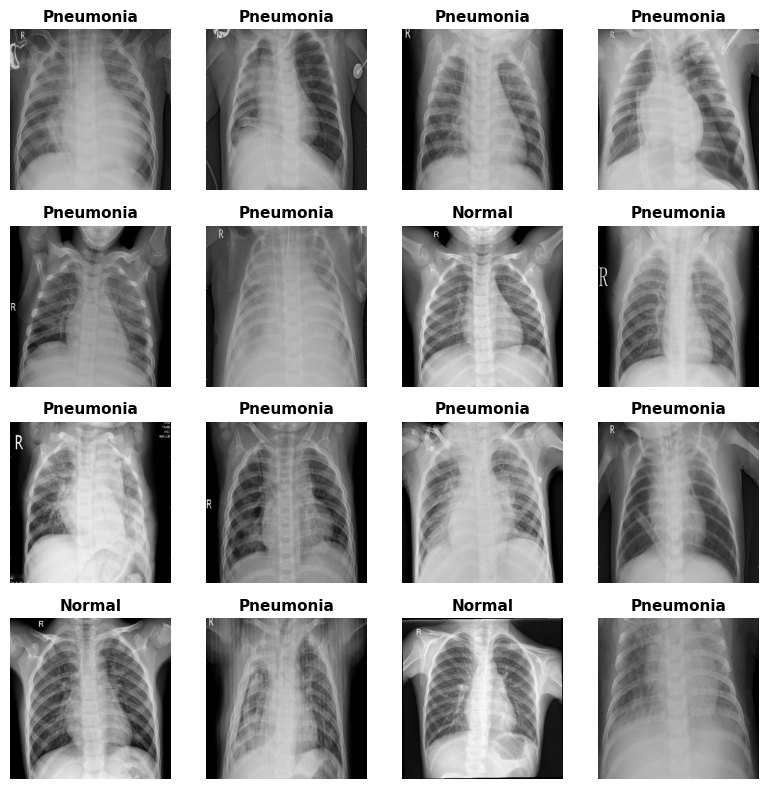

In [11]:
class_names = ['Normal', 'Pneumonia']

for images, labels in train_ds.take(1):
    plt.figure(figsize=(8,8))
    for i in range(16):
        ax = plt.subplot(4,4,i+1)
        img = images[i].numpy().astype('uint8')   
        lbl_index = labels[i].numpy()
        title_text = class_names[lbl_index]
        plt.imshow(img)
        plt.title(title_text, fontsize=11, fontweight='bold')
        plt.axis("off")
plt.tight_layout()
plt.show()

# Model

In [12]:

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',         
    patience=10,                 
    restore_best_weights=True,  
    verbose=1
)


model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath='best_chest_xray_model.keras', 
    monitor='val_loss',
    save_best_only=True,                    
    verbose=1
)


reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,                 
    patience=2,                
    min_lr=1e-6,                
    verbose=1
)

 ## Define the Model

In [15]:
from tensorflow.keras import layers, regularizers

with strategy.scope():

    data_augmentation = tf.keras.Sequential([
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomTranslation(0.05, 0.05),
        layers.RandomContrast(0.1),
    ], name='augmentation')

    base_vgg = tf.keras.applications.VGG16(
        weights='imagenet',
        include_top=False,
        input_shape=(384, 384, 3)
    )
    base_vgg.trainable = False

    inputs = tf.keras.Input(shape=(384, 384, 3))
    x = data_augmentation(inputs)
    x = preprocess_input(x)
    x = base_vgg(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(256, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)

    x = layers.Dense(64, activation='relu',
                     kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(1, activation='sigmoid', name='Output')(x)

    model = tf.keras.Model(inputs, outputs)

    metrics = [
        tf.keras.metrics.BinaryAccuracy(name='accuracy'),
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall'),
    ]

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss=tf.keras.losses.BinaryCrossentropy(), 
        metrics=metrics
    )

def make_callbacks(ckpt_path):
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=5, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(
            ckpt_path, monitor='val_loss', save_best_only=True),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7),
    ]

# Phase 1: train only the head
history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=make_callbacks('phase1_best.keras')
)

# Phase 2: unfreeze block5 only, with a very small learning rate
with strategy.scope():
    base_vgg.trainable = True
    for layer in base_vgg.layers:
        layer.trainable = layer.name.startswith('block5')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(1e-5),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=metrics
    )

history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=make_callbacks('phase2_best.keras')
)

INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Reduce to /job:localhost/replica:0/task:0/device:CPU:0 then broadcast to ('/job:localhost/replica:0/task:0/device:CPU:0',).
INFO:tensorflow:Redu

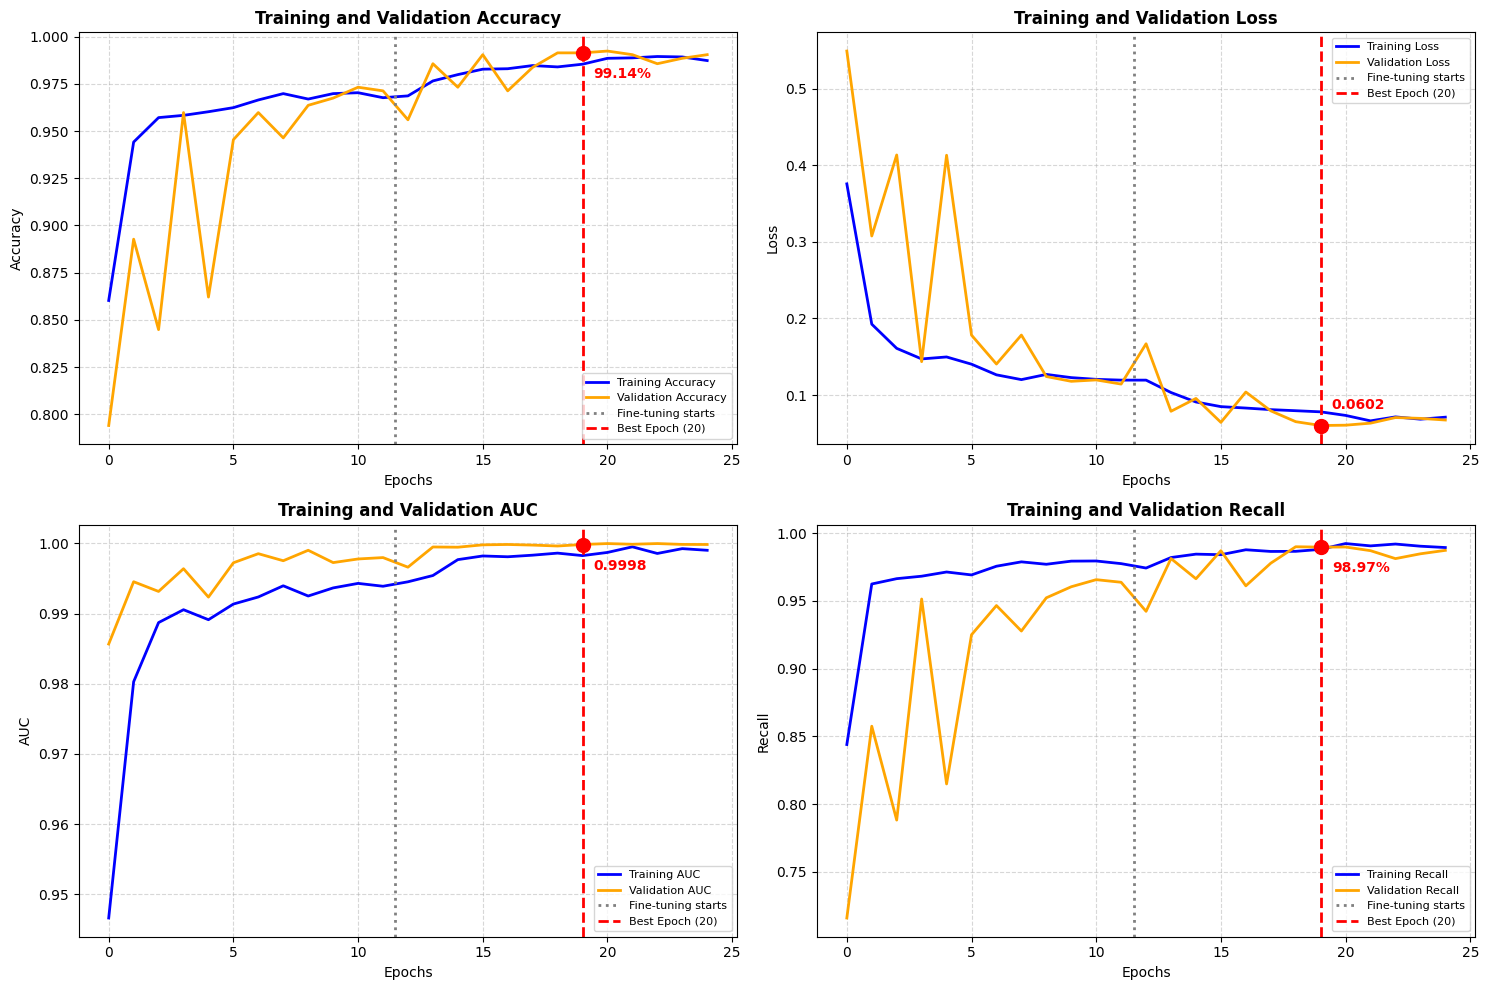

🎯 Best Epoch      : 20  (phase 2)
✅ Best Val Acc    : 99.14%
✅ Best Val Loss   : 0.0602
✅ Best Val AUC    : 0.9998
✅ Best Val Recall : 98.97%
✅ Best Val Prec.  : 99.87%


In [16]:
# Merge phase 1 (head only) and phase 2 (fine-tuning) into one history
def merge_histories(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

hist = merge_histories(history_1, history_2)
n_phase1 = len(history_1.history['loss'])

acc, val_acc = hist['accuracy'], hist['val_accuracy']
loss, val_loss = hist['loss'], hist['val_loss']
auc, val_auc = hist['auc'], hist['val_auc']
rec, val_rec = hist['recall'], hist['val_recall']

best_epoch = val_loss.index(min(val_loss))


def plot_metric(ax, train, val, title, ylabel, best_epoch, fmt, legend_loc, higher_is_better=True):
    ax.plot(train, label=f'Training {ylabel}', color='blue', linewidth=2)
    ax.plot(val, label=f'Validation {ylabel}', color='orange', linewidth=2)

    # Where fine-tuning starts
    ax.axvline(x=n_phase1 - 0.5, color='gray', linestyle=':', linewidth=2,
               label='Fine-tuning starts')

    # Best epoch (chosen by val_loss)
    ax.axvline(x=best_epoch, color='red', linestyle='--', linewidth=2,
               label=f'Best Epoch ({best_epoch + 1})')
    ax.scatter(best_epoch, val[best_epoch], color='red', s=100, zorder=5)
    ax.annotate(fmt(val[best_epoch]),
                xy=(best_epoch, val[best_epoch]),
                xytext=(8, -18 if higher_is_better else 12),
                textcoords='offset points',
                fontsize=10, color='red', fontweight='bold')

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Epochs', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc=legend_loc, fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(15, 10))

plot_metric(axes[0, 0], acc, val_acc, 'Training and Validation Accuracy', 'Accuracy',
            best_epoch, lambda v: f'{v*100:.2f}%', 'lower right')
plot_metric(axes[0, 1], loss, val_loss, 'Training and Validation Loss', 'Loss',
            best_epoch, lambda v: f'{v:.4f}', 'upper right', higher_is_better=False)
plot_metric(axes[1, 0], auc, val_auc, 'Training and Validation AUC', 'AUC',
            best_epoch, lambda v: f'{v:.4f}', 'lower right')
plot_metric(axes[1, 1], rec, val_rec, 'Training and Validation Recall', 'Recall',
            best_epoch, lambda v: f'{v*100:.2f}%', 'lower right')

plt.tight_layout()
plt.show()

print("=" * 50)
print(f"🎯 Best Epoch      : {best_epoch + 1}  (phase {1 if best_epoch < n_phase1 else 2})")
print(f"✅ Best Val Acc    : {val_acc[best_epoch] * 100:.2f}%")
print(f"✅ Best Val Loss   : {val_loss[best_epoch]:.4f}")
print(f"✅ Best Val AUC    : {val_auc[best_epoch]:.4f}")
print(f"✅ Best Val Recall : {val_rec[best_epoch] * 100:.2f}%")
print(f"✅ Best Val Prec.  : {hist['val_precision'][best_epoch] * 100:.2f}%")
print("=" * 50)